# Weibull calibration of simulated AlSi10Mg yield strength

Calibrates the simulated (model-based UQ) yield-strength population for one layer thickness against the experimental tensile data, and estimates minimum strengths at the 1st and 10th percentiles.

Steps:
1. Calibrate the simulated population to the experimental mean and standard deviation (Harlow, 2007).
2. Fit a three-parameter (shifted) Weibull distribution to the experimental data with PyMC (uniform priors).
3. Use that posterior, via kernel density estimates, as the prior for a fit to the calibrated population.
4. Estimate minimum strengths from the 25th percentile of the posterior 1st and 10th percentiles, adjusted for simulation error.

Diagnostic fits to the uncalibrated and calibrated populations alone are included for comparison.

Run with papermill for each layer thickness (see `code/run_all.py`), or set `LAYER_THICKNESS_UM` below and run all cells in order.
Outputs are written to `data/weibull/`, `data/posterior/` and `figures/`.

In [1]:
LAYER_THICKNESS_UM = 30
CORES = None   # parallel chains; None lets PyMC decide. Results do not depend on this.

In [2]:
# Parameters
LAYER_THICKNESS_UM = 60
CORES = 1


In [3]:
from pathlib import Path
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import pymc as pm
import pytensor
import arviz as az

for m in (np, scipy, pd, matplotlib, pm, pytensor, az):
    print(f"{m.__name__} {m.__version__}")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


numpy 1.26.4
scipy 1.17.1
pandas 3.0.2
matplotlib 3.10.8
pymc 5.16.2
pytensor 2.25.5
arviz 0.19.0


In [4]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
(DATA / "posterior").mkdir(exist_ok=True)

LT = int(LAYER_THICKNESS_UM)
TAG = f"lt{LT}um"

# Fixed seeds so the posterior samples reproduce exactly with the pinned package versions
SEEDS = {"uncalibrated": 101, "calibrated_population": 102, "experiment": 103, "full": 104}
SUBSAMPLE_SEED = 42          # simulation-error subsampling, as in the original analysis

# Plot limits and full-model initial values per layer thickness.
# 30 µm values are those used in the original analysis.
SETTINGS = {
    30: {"xlim": (148, 180), "full_initvals": {"gamma": 145.0, "alpha": 1.827, "beta": 9.13}},
    60: {"xlim": None, "full_initvals": None},
}
settings = SETTINGS[LT]
plot_xlabel = "0.2% Yield Strength (MPa)"

## Load data

In [5]:
tensile = pd.read_csv(DATA / "tensile" / "tensile_tests.csv")
population = pd.read_csv(DATA / "simulated" / "simulated_populations.csv")

exp_data = tensile.loc[tensile["layer_thickness_um"] == LT, "yield_strength_MPa_calibration"].to_numpy()
pop = population[(population["layer_thickness_um"] == LT) & (population["property"] == "yield_strength")].sort_values("sample_id")
total_strength_array = pop["value_original_MPa"].to_numpy()

assert len(exp_data) > 0 and not np.isnan(exp_data).any(), "missing experimental values"
assert len(total_strength_array) == 1500
print(f"{LT} µm: {len(exp_data)} experimental values, {len(total_strength_array)} simulated values")

exp_data_array = exp_data
x_lower, x_upper = settings["xlim"] or (
    np.floor(min(exp_data.min(), total_strength_array.min())) - 2,
    np.ceil(max(exp_data.max(), total_strength_array.max())) + 2,
)

60 µm: 61 experimental values, 1500 simulated values


## Calibration (Harlow, 2007)

In [6]:
def AIM_calibration(exp_data: np.ndarray, model_data: np.ndarray) -> np.ndarray:
    """
    Calibrates model predictions to match experimental data using a probabilistic property
    prediction method based on the work by D.G. Harlow (2007)

    Parameters:
    - exp_data (array-like): Experimental data values (can contain NaNs)
    - model_data (array-like): Model prediction values (can contain NaNs)

    Returns:
    - model_calibrated (np.ndarray): Calibrated model predictions aligned with the experimental data
    """
    # Filter out NaN values from both datasets
    exp_data_clean = np.array(exp_data)[~np.isnan(exp_data)]
    model_data_clean = np.array(model_data)[~np.isnan(model_data)]

    # Verify there is data to process
    if len(exp_data_clean) == 0 or len(model_data_clean) == 0:
        raise ValueError("Both 'exp_data' and 'model_data' must contain at least one non-NaN value.")

    # Calculate standard deviations and means
    exp_std, model_std = np.std(exp_data_clean), np.std(model_data_clean)
    exp_mean, model_mean = np.mean(exp_data_clean), np.mean(model_data_clean)

    # Calculate calibration coefficients 'a' (scaling) and 'b' (shifting)
    a = exp_std / model_std
    b = exp_mean - a * model_mean

    # Apply calibration to model data
    model_calibrated = a * model_data_clean + b

    return model_calibrated


def median_rank_estimate(data: np.ndarray) -> np.ndarray:
    """
    Median ranks by Benard's approximation, (i - 0.3) / (n + 0.4), for sorted data.
    Reference: http://reliawiki.org/index.php/The_Weibull_Distribution
    """
    clean_data = data[~np.isnan(data)]
    n = len(clean_data)
    if n < 1:
        raise ValueError("Input data must contain at least one non-NaN value.")
    return (np.arange(1, n + 1) - 0.3) / (n + 0.4)


def AIM_plot(exp_data: np.ndarray, model_data: np.ndarray):
    calibrated_data = AIM_calibration(exp_data, model_data)
    data = {"Experiment": exp_data, "Calibrated": calibrated_data, "Uncalibrated": model_data}

    plt.figure(figsize=(10, 7))
    for set_name, values in data.items():
        sorted_data = np.sort(values)
        median_ranks = median_rank_estimate(sorted_data)
        weibull_transform = np.log(-np.log(1 - median_ranks))
        style = "o" if set_name == "Experiment" else "-"
        plt.plot(sorted_data, weibull_transform, style, label=set_name)

    plt.xlabel(plot_xlabel)
    plt.ylabel("Cumulative Probability")
    labels = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 90, 99, 99.9]
    y_ticks = np.log(-np.log(1 - np.array(labels) / 100))
    plt.yticks(ticks=y_ticks, labels=labels)
    plt.grid(True)
    plt.xlim(x_lower, x_upper)
    plt.legend(facecolor="white", framealpha=1, fontsize="large", loc="upper left")
    plt.savefig(FIG / f"{TAG}_weibull_probability_plot.png", bbox_inches="tight", pad_inches=0.01, dpi=300)
    plt.show()
    return calibrated_data

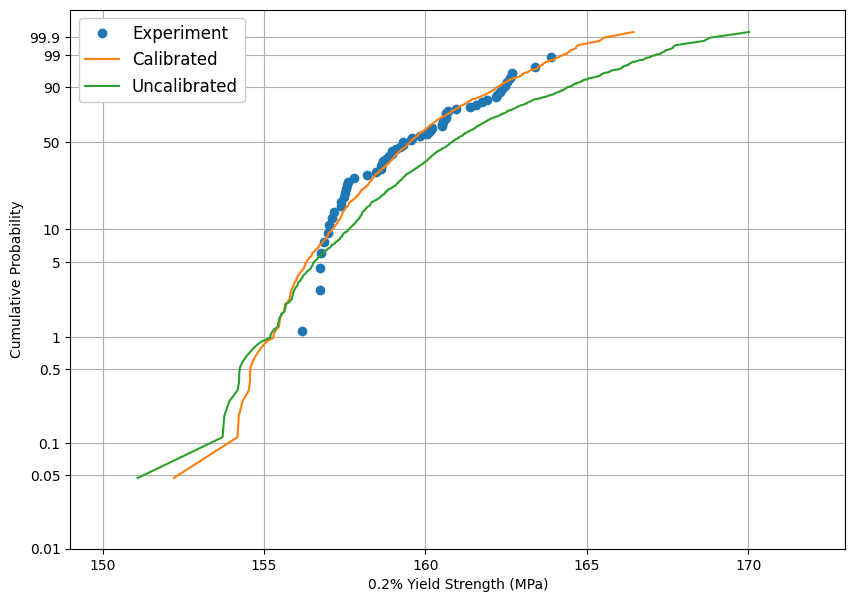

Calibrated population matches the deposited data.


In [7]:
model_calibrated = AIM_plot(exp_data_array, total_strength_array)

# The deposited calibrated population must be exactly what this code produces
assert np.allclose(model_calibrated, pop["value_calibrated_MPa"].to_numpy(), rtol=0, atol=1e-5), \
    "calibrated population does not match data/simulated/simulated_populations.csv"
print("Calibrated population matches the deposited data.")

## Maximum-likelihood Weibull fits (scipy)

Experiment: shape=1.9433, location=155.8773, scale=4.1638
  p01=156.27, p10=157.19, p90=162.27, p99=165.01


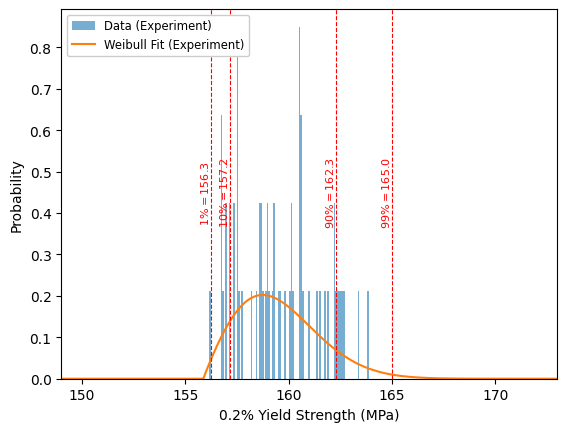

Uncalibrated: shape=4.2403, location=150.7083, scale=11.1792
  p01=154.49, p10=157.28, p90=164.32, p99=166.73


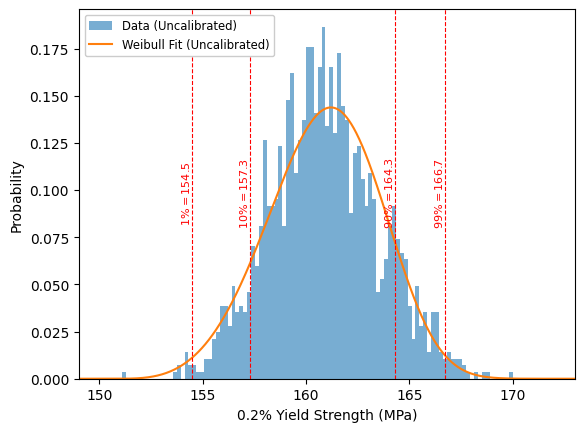

Calibrated: shape=4.2403, location=151.9176, scale=8.4042
  p01=154.76, p10=156.86, p90=162.15, p99=163.97


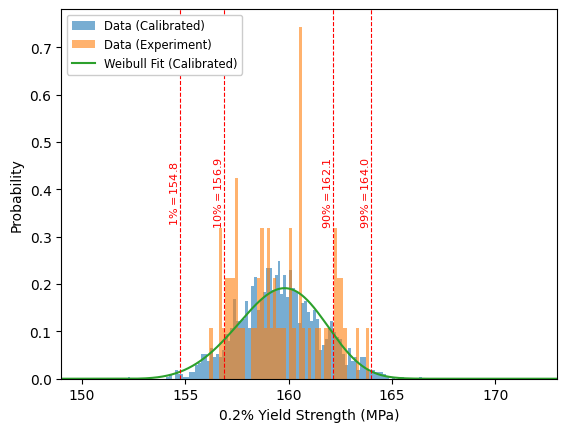

In [8]:
PERCENTILES = {"p01": 0.01, "p10": 0.10, "p90": 0.90, "p99": 0.99}
rows = []

def scipy_fit(data, label, dataset, filename=None, overlay_exp=False):
    data = np.sort(data)
    params = scipy.stats.weibull_min.fit(data)
    dist = scipy.stats.weibull_min(*params)
    q = dict(zip(PERCENTILES, dist.ppf(list(PERCENTILES.values()))))
    print(f"{label}: shape={params[0]:.4f}, location={params[1]:.4f}, scale={params[2]:.4f}")
    print("  " + ", ".join(f"{k}={v:.2f}" for k, v in q.items()))

    fig, ax = plt.subplots()
    plt.hist(data, bins=100, density=True, alpha=0.6, label=f"Data ({label})")
    if overlay_exp:
        plt.hist(exp_data, density=True, bins=50, alpha=0.6, label="Data (Experiment)")
    xvals = np.linspace(x_lower, x_upper, 1000)
    plt.plot(xvals, dist.pdf(xvals), label=f"Weibull Fit ({label})")
    plt.xlim(x_lower, x_upper)
    for name in ["p01", "p10", "p90", "p99"]:
        plt.axvline(q[name], color="r", ls="--", lw=0.8)
        plt.text(q[name], 0.5, f" ${PERCENTILES[name]*100:g}\\% = {q[name]:.1f}$", color="r",
                 ha="right", va="center", rotation=90, transform=ax.get_xaxis_transform(), fontsize=8)
    plt.xlabel(plot_xlabel)
    plt.ylabel("Probability")
    plt.legend(facecolor="white", framealpha=1, fontsize="small", loc="upper left")
    if filename:
        plt.savefig(FIG / filename, bbox_inches="tight", pad_inches=0.01, dpi=300)
    plt.show()

    for name, value in zip(["alpha", "gamma", "beta"], params):
        rows.append({"dataset": dataset, "method": "scipy_mle", "parameter": name, "estimate": value})
    for name, value in q.items():
        rows.append({"dataset": dataset, "method": "scipy_mle", "parameter": name, "estimate": value})

scipy_fit(exp_data, "Experiment", "experimental", f"{TAG}_density_experiment.png")
scipy_fit(total_strength_array, "Uncalibrated", "uncalibrated_population", f"{TAG}_density_uncalibrated.png")
scipy_fit(model_calibrated, "Calibrated", "calibrated_population", f"{TAG}_density_calibrated.png", overlay_exp=True)

## Shifted (three-parameter) Weibull distribution for PyMC

In [9]:
from pymc.distributions.continuous import RandomVariable, Continuous, pt, check_parameters, check_icdf_value
from pymc.distributions.shape_utils import rv_size_is_none

warnings.filterwarnings("ignore", message="ndim_supp is deprecated")
warnings.filterwarnings("ignore", message="ndims_params is deprecated")


class ShiftedWeibullBetaRV(RandomVariable):
    name = "shifted_weibull"
    ndim_supp = 0
    ndims_params = [0, 0, 0]
    dtype = "floatX"
    _print_name = ("ShiftedWeibull", "\\operatorname{ShiftedWeibull}")

    def __call__(self, gamma, alpha, beta, size=None, **kwargs):
        return super().__call__(gamma, alpha, beta, size=size, **kwargs)

    @classmethod
    def rng_fn(cls, rng, gamma, alpha, beta, size) -> np.ndarray:
        return np.asarray(gamma + beta * rng.weibull(alpha, size=size))


shifted_weibull_beta = ShiftedWeibullBetaRV()


class ShiftedWeibull(Continuous):
    r"""
    Three-parameter Weibull distribution with location gamma, shape alpha and scale beta.

    f(x | gamma, alpha, beta) = (alpha / beta) ((x - gamma) / beta)^(alpha - 1) exp(-((x - gamma) / beta)^alpha),  x >= gamma
    """

    rv_op = shifted_weibull_beta

    @classmethod
    def dist(cls, gamma, alpha, beta, *args, **kwargs):
        gamma = pt.as_tensor_variable(gamma)
        alpha = pt.as_tensor_variable(alpha)
        beta = pt.as_tensor_variable(beta)
        return super().dist([gamma, alpha, beta], *args, **kwargs)

    def moment(rv, size, gamma, alpha, beta):
        mean = gamma + beta * pt.gamma(1 + 1 / alpha)
        if not rv_size_is_none(size):
            mean = pt.full(size, mean)
        return mean

    def logcdf(value, gamma, alpha, beta):
        value_shifted = value - gamma
        a = (value_shifted / beta) ** alpha
        res = pt.switch(pt.lt(value_shifted, 0), -np.inf, pt.log1mexp(-a))
        return check_parameters(res, alpha > 0, beta > 0, msg="alpha > 0, beta > 0")

    def logp(value, gamma, alpha, beta):
        value_shifted = value - gamma
        res = (
            pt.log(alpha)
            - pt.log(beta)
            + (alpha - 1.0) * pt.log(value_shifted / beta)
            - pt.pow(value_shifted / beta, alpha)
        )
        res = pt.switch(pt.ge(value_shifted, 0.0), res, -np.inf)
        return check_parameters(res, alpha > 0, beta > 0, msg="alpha > 0, beta > 0")

    def icdf(value, gamma, alpha, beta):
        res = beta * (-pt.log(1 - value)) ** (1 / alpha)
        res = check_icdf_value(res, value) + gamma
        return check_parameters(res, alpha > 0, beta > 0, msg="alpha > 0, beta > 0")


def add_percentiles(gamma, alpha, beta):
    for name, q in PERCENTILES.items():
        pm.Deterministic(name, ShiftedWeibull.icdf(q, gamma, alpha, beta))


def sample(target_accept, seed, initvals=None):
    return pm.sample(draws=2000, tune=1000, step=pm.NUTS(target_accept=target_accept), chains=4,
                     cores=CORES, progressbar=False, init="adapt_diag_grad", initvals=initvals,
                     random_seed=seed, return_inferencedata=True)

## Diagnostic fits to the simulated populations alone

Uniform priors on `gamma`, `alpha` and `beta`.

In [10]:
def population_model(data):
    with pm.Model() as model:
        gamma = pm.Uniform("gamma", lower=min(data) - 10 * np.std(data), upper=min(data))
        alpha = pm.Uniform("alpha", lower=1.5, upper=10)
        beta = pm.Uniform("beta", lower=5, upper=15)
        ShiftedWeibull("obs", gamma=gamma, alpha=alpha, beta=beta, observed=data)
        add_percentiles(gamma, alpha, beta)
    return model

uncalibrated_model = population_model(total_strength_array)
with uncalibrated_model:
    uncalibrated_model_trace = sample(0.98, SEEDS["uncalibrated"])

calibrated_model = population_model(model_calibrated)
with calibrated_model:
    calibrated_model_trace = sample(0.98, SEEDS["calibrated_population"])

Sequential sampling (4 chains in 1 job)


NUTS: [gamma, alpha, beta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 70 seconds.


Sequential sampling (4 chains in 1 job)


NUTS: [gamma, alpha, beta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 69 seconds.


## Posterior from the experimental data

Uniform priors on `gamma`, `alpha` and `beta`.

In [11]:
with pm.Model() as experiment_model:
    gamma = pm.Uniform("gamma", min(exp_data) - 10 * np.std(exp_data), min(exp_data))
    alpha = pm.Uniform("alpha", 1.5, 10)
    beta = pm.Uniform("beta", 0, 15)
    ShiftedWeibull("obs", gamma=gamma, alpha=alpha, beta=beta, observed=exp_data)
    add_percentiles(gamma, alpha, beta)
    experiment_model_trace = sample(0.98, SEEDS["experiment"])

Sequential sampling (4 chains in 1 job)


NUTS: [gamma, alpha, beta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 61 seconds.


## Final posterior: experimental posterior updated with the calibrated population

The experimental posteriors for `alpha`, `beta` and `gamma` become the priors, built by kernel density estimation and interpolation.

In [12]:
from pymc.distributions import Interpolated

def from_posterior(param, samples):
    samples = samples.stack(sample=["chain", "draw"])
    smin, smax = np.min(samples), np.max(samples)
    width = smax - smin
    x = np.linspace(smin, smax, 100)
    y = scipy.stats.gaussian_kde(samples)(x)
    # what was never sampled should have a small probability but not 0,
    # so extend the domain and use a linear approximation of the density on it
    x = np.concatenate([[x[0] - 3 * width], x, [x[-1] + 3 * width]])
    y = np.concatenate([[0], y, [0]])
    return Interpolated(param, x, y)

with pm.Model() as full_model:
    gamma = from_posterior("gamma", experiment_model_trace.posterior["gamma"])
    alpha = from_posterior("alpha", experiment_model_trace.posterior["alpha"])
    beta = from_posterior("beta", experiment_model_trace.posterior["beta"])
    ShiftedWeibull("obs", gamma=gamma, alpha=alpha, beta=beta, observed=model_calibrated)
    add_percentiles(gamma, alpha, beta)

    # Initial values: gamma must start below the smallest calibrated value
    initvals = settings["full_initvals"] or {
        "gamma": float(np.floor(min(model_calibrated))),
        "alpha": float(experiment_model_trace.posterior["alpha"].mean()),
        "beta": float(experiment_model_trace.posterior["beta"].mean()),
    }
    print("initvals:", initvals)
    full_model_trace = sample(0.99, SEEDS["full"], initvals=initvals)

initvals: {'gamma': 152.0, 'alpha': 3.0930795586449285, 'beta': 6.283434492481643}


Sequential sampling (4 chains in 1 job)


NUTS: [gamma, alpha, beta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 116 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


## Diagnostics

In [13]:
traces = {
    "uncalibrated_population": uncalibrated_model_trace,
    "calibrated_population": calibrated_model_trace,
    "experimental": experiment_model_trace,
    "calibrated_bayesian_update": full_model_trace,
}
for name, tr in traces.items():
    div = int(tr.sample_stats["diverging"].sum())
    print(f"{name}: {div} divergences after tuning")
    print(az.summary(tr, var_names=["gamma", "alpha", "beta"], round_to=3)[["mean", "sd", "r_hat", "ess_bulk"]], "\n")

uncalibrated_population: 0 divergences after tuning
          mean     sd  r_hat  ess_bulk
gamma  150.587  0.256  1.001  1392.958
alpha    4.287  0.134  1.002  1489.218
beta    11.304  0.275  1.001  1389.787 

calibrated_population: 0 divergences after tuning
          mean     sd  r_hat  ess_bulk
gamma  151.805  0.211  1.002  1247.581
alpha    4.300  0.146  1.001  1371.923
beta     8.521  0.225  1.002  1269.513 

experimental: 0 divergences after tuning
          mean     sd  r_hat  ess_bulk
gamma  153.944  2.392  1.004   699.127
alpha    3.093  1.377  1.006   721.066
beta     6.283  2.506  1.005   771.120 

calibrated_bayesian_update: 2 divergences after tuning
          mean     sd  r_hat  ess_bulk
gamma  151.834  0.191  1.002  1128.413
alpha    4.281  0.138  1.003  1315.641
beta     8.489  0.205  1.002  1097.081 



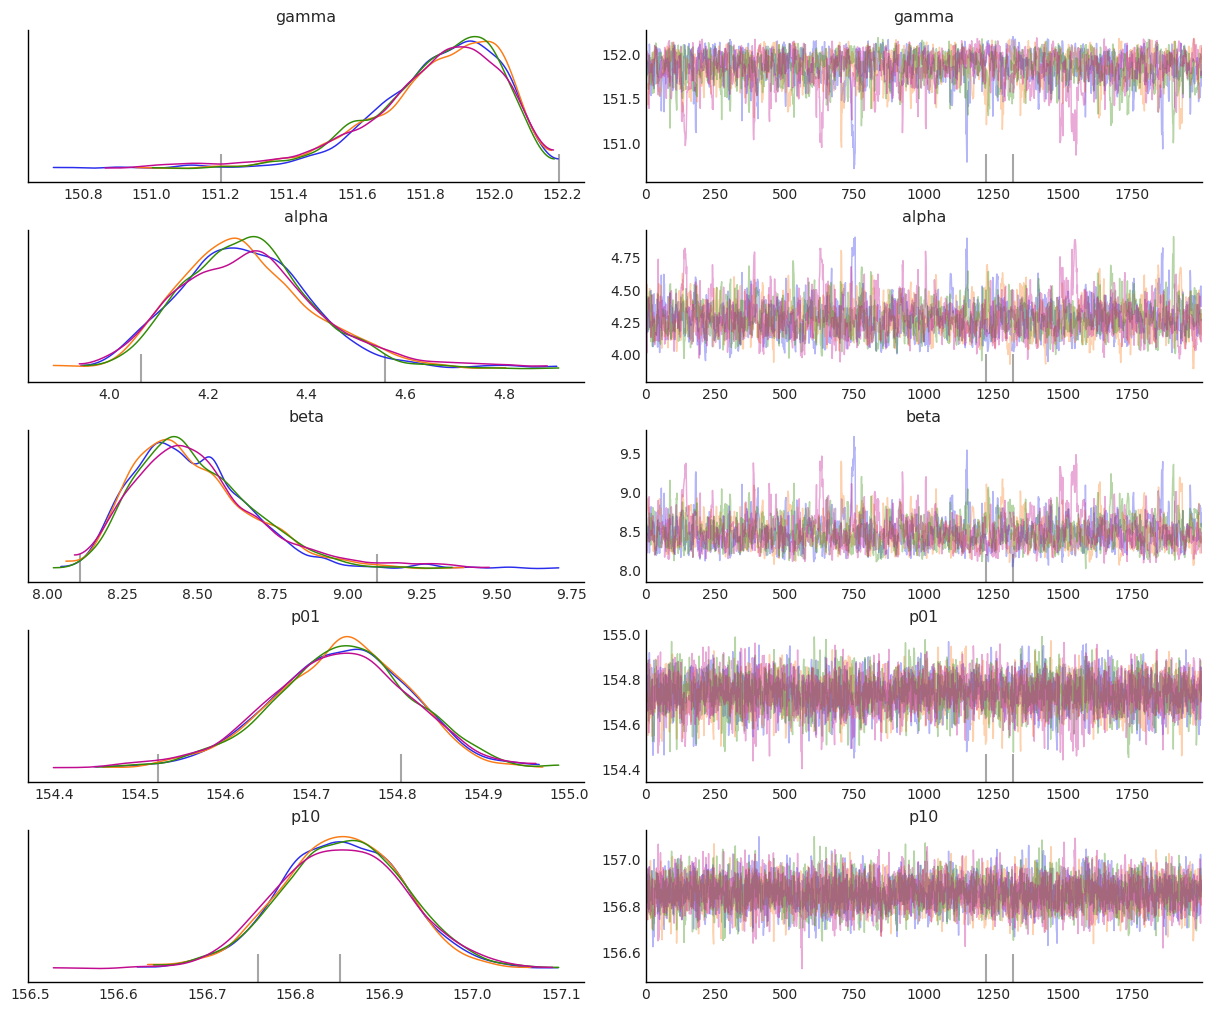

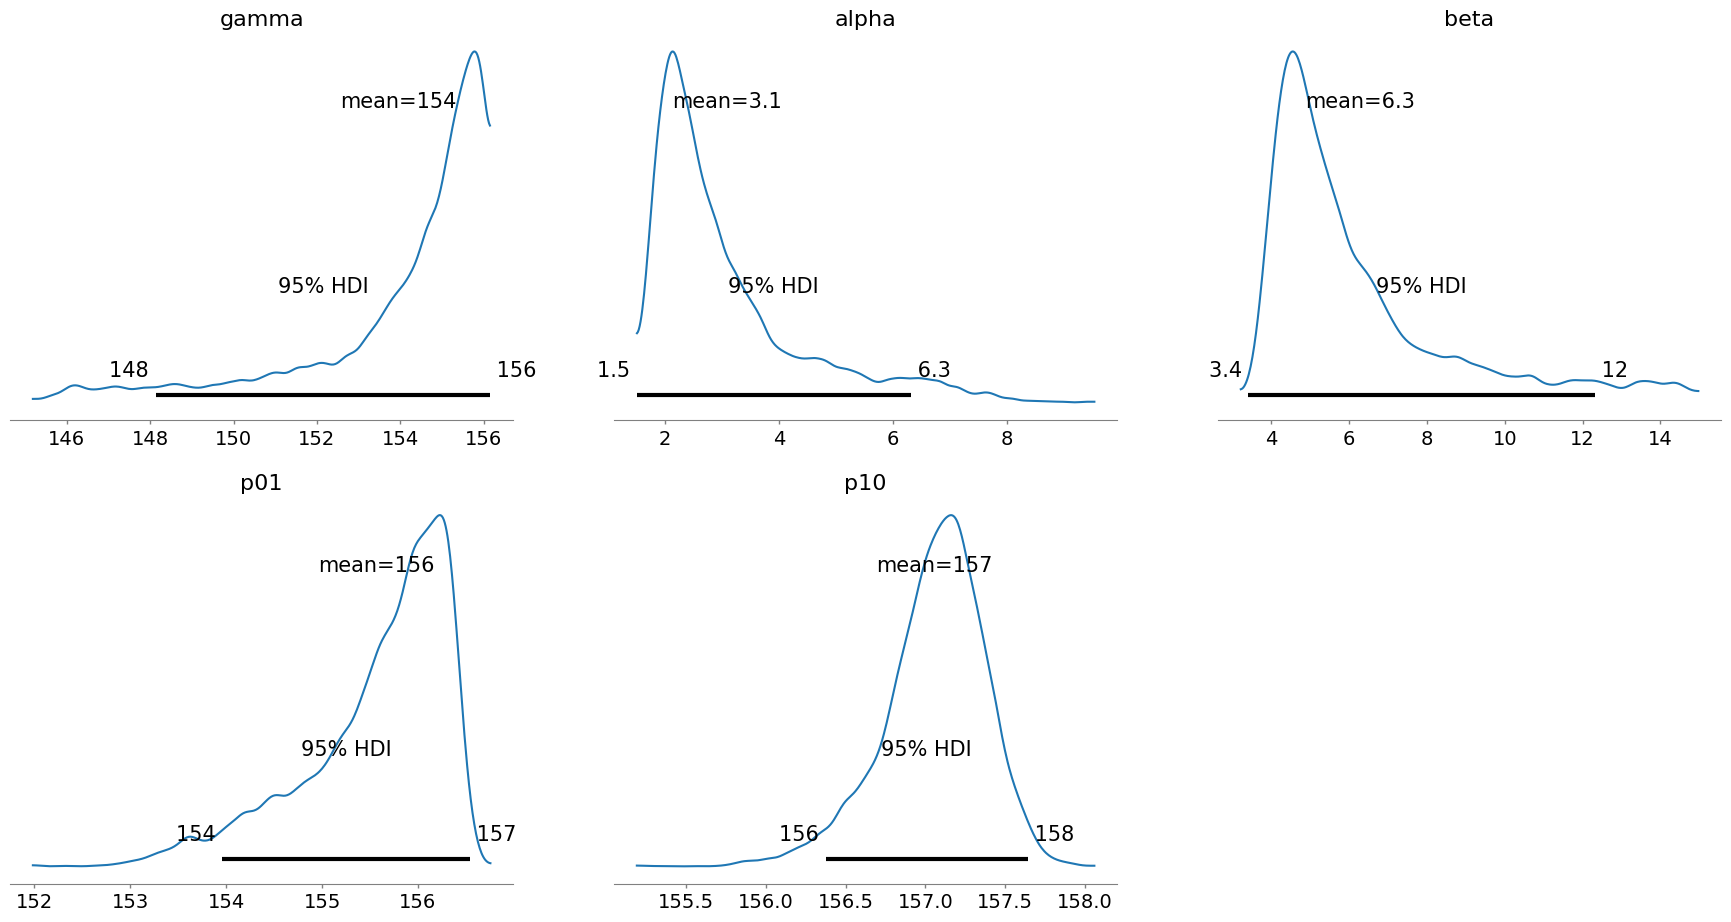

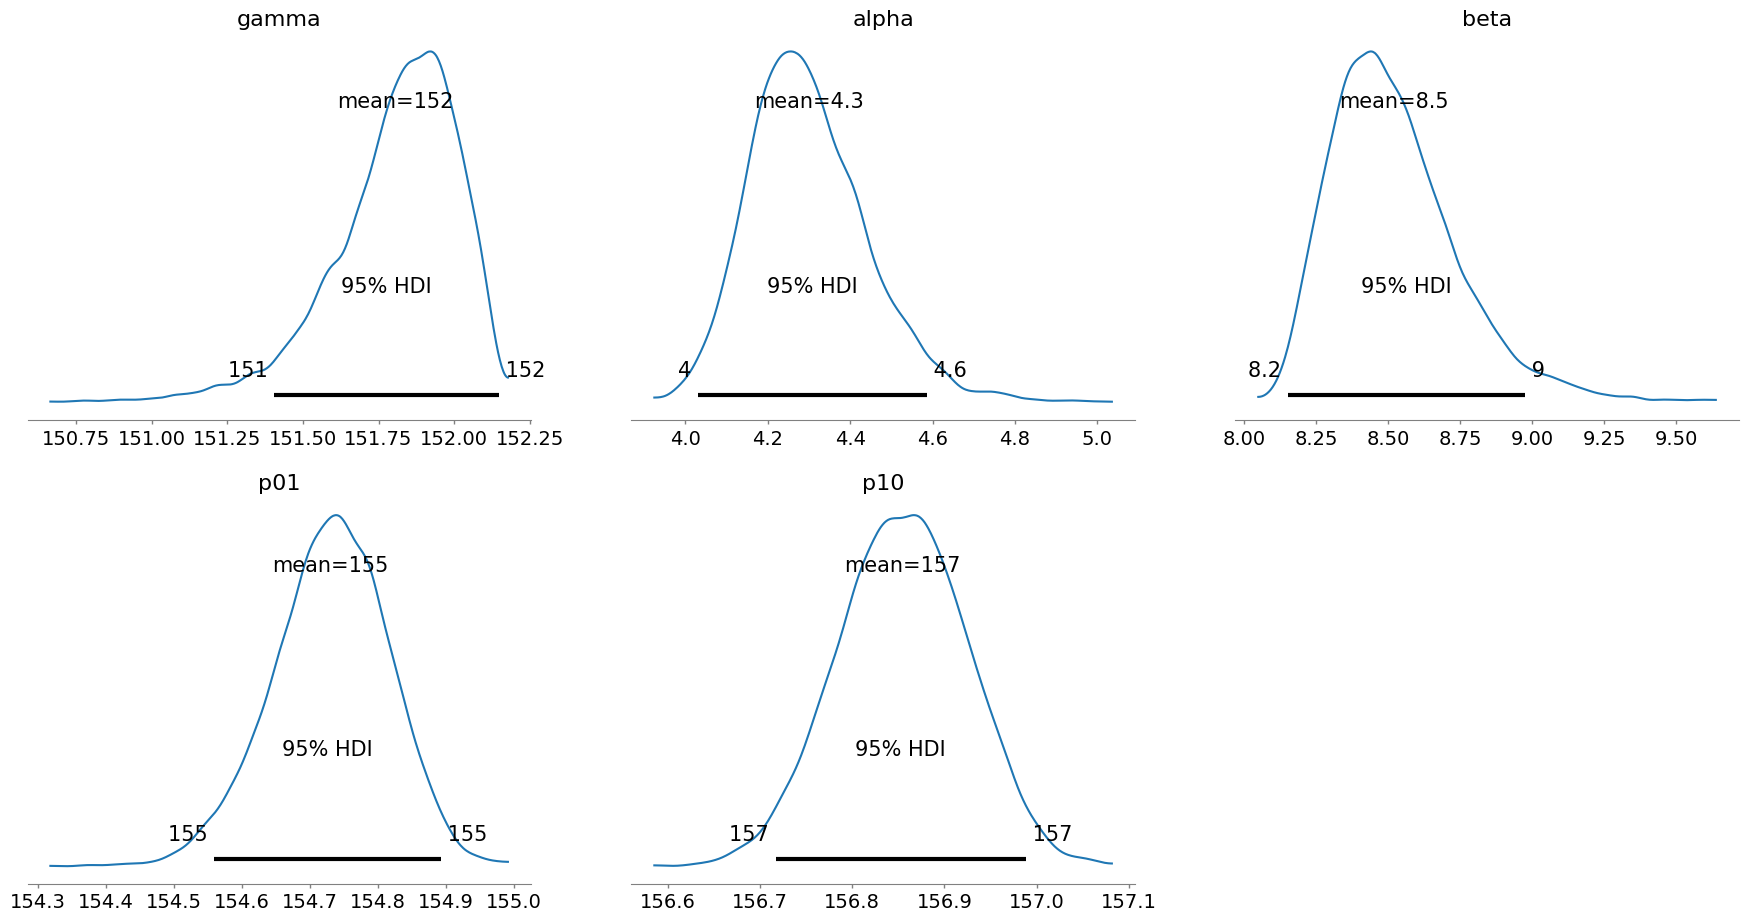

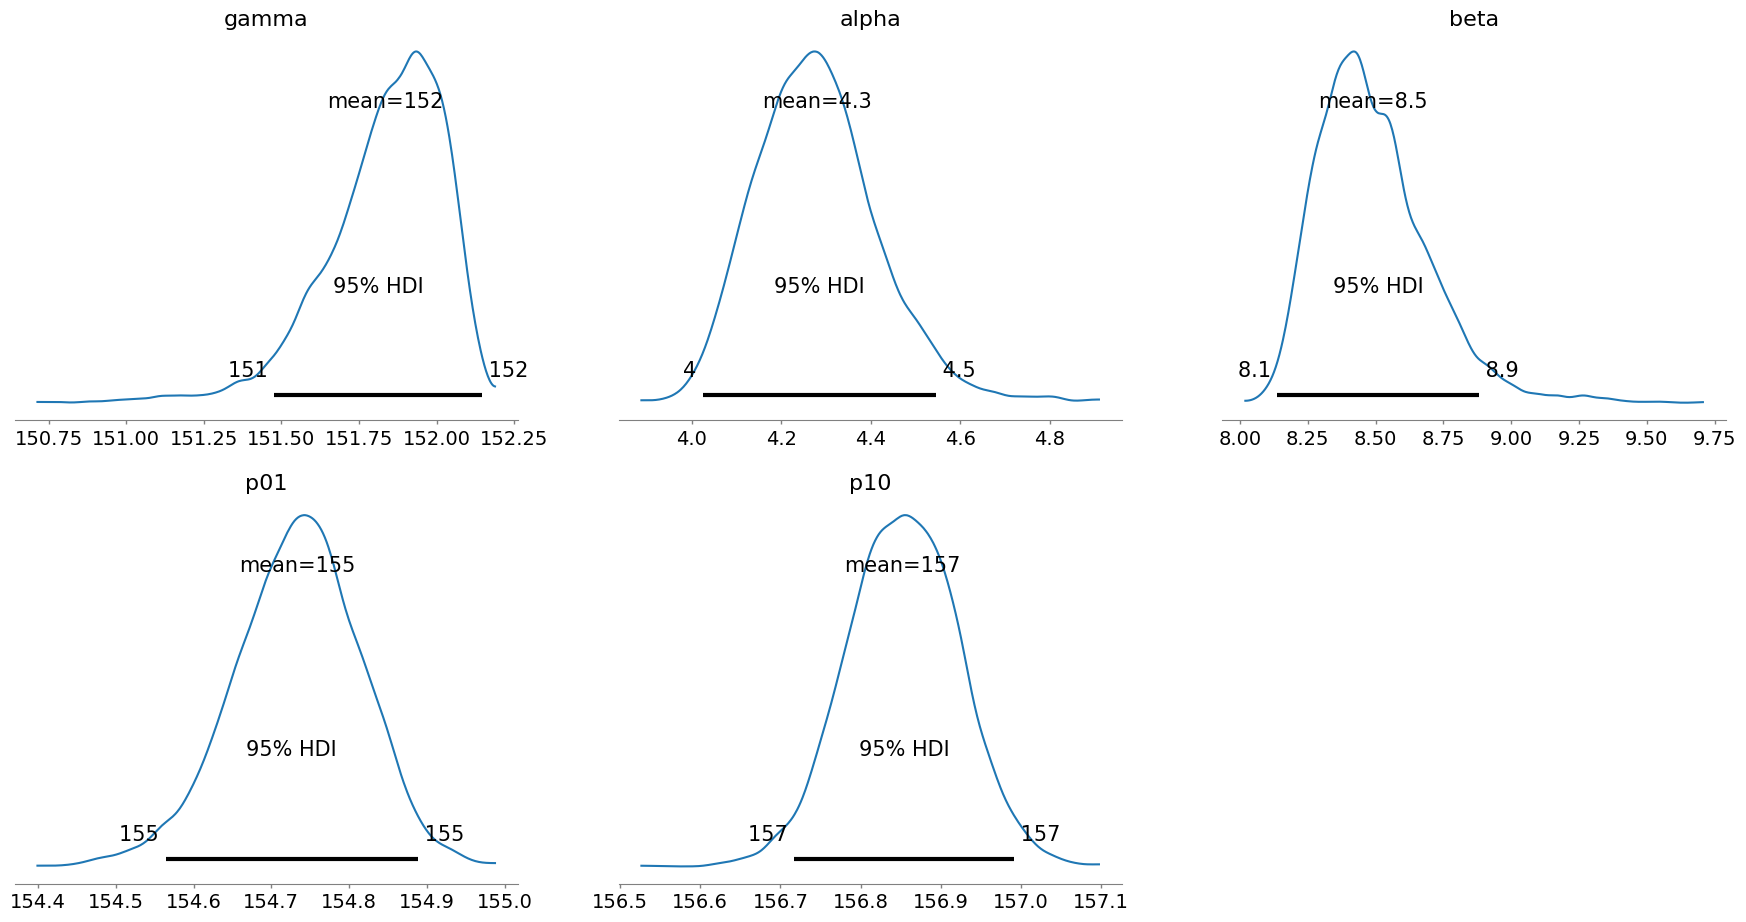

In [14]:
az.style.use("arviz-white")
axes = az.plot_trace(full_model_trace, var_names=["gamma", "alpha", "beta", "p01", "p10"], compact=False)
axes.ravel()[0].figure.savefig(FIG / f"{TAG}_trace_full.png", bbox_inches="tight", pad_inches=0.01, dpi=300)
az.style.use("default")

for name, tr in [("experimental", experiment_model_trace), ("calibrated_population", calibrated_model_trace),
                 ("full", full_model_trace)]:
    axes = az.plot_posterior(tr, var_names=["gamma", "alpha", "beta", "p01", "p10"], hdi_prob=0.95)
    axes.ravel()[0].figure.savefig(FIG / f"{TAG}_posterior_{name}.png", bbox_inches="tight", pad_inches=0.01, dpi=300)
    plt.show()

## Variance due to simulation error

`model_calibrated` and `exp_data` have different sample sizes, so `model_calibrated` is subsampled to the experimental sample size many times and the results are averaged.

In [15]:
np.random.seed(SUBSAMPLE_SEED)

exp_data_arr = np.sort(np.array(exp_data))
# Sorted ascending, the order of the original input file, so the seeded subsampling reproduces the original result
model_calibrated_arr = np.sort(np.array(model_calibrated))

variance_due_to_simulation_samples = []
num_samples = 20_000
for i in range(num_samples):
    model_calibrated_sample = np.random.choice(model_calibrated_arr, size=len(exp_data_arr))
    model_calibrated_sample.sort()
    variance_due_to_simulation_samples.append(((exp_data_arr - model_calibrated_sample) ** 2).mean())

variance_due_to_simulation = np.mean(variance_due_to_simulation_samples)
variance_due_to_simulation_stderr = np.std(variance_due_to_simulation_samples) / num_samples ** 0.5
print(f"variance_due_to_simulation: {variance_due_to_simulation} (stderr = {variance_due_to_simulation_stderr})")

variance_due_to_simulation: 0.2761544195790979 (stderr = 0.0009629733706252453)


## Minimum strength

The 25th percentile of the posterior samples of the 1st and 10th percentiles, adjusted for simulation error.

In [16]:
minimum = []
for name in ["p01", "p10"]:
    q25 = full_model_trace.posterior[name].quantile(0.25).item()
    guaranteed = q25 - 2 / 3 * variance_due_to_simulation
    print(f"{name}: posterior 25th percentile = {q25:.3f} MPa, guaranteed minimum strength = {guaranteed:.3f} MPa")
    minimum.append({
        "layer_thickness_um": LT,
        "percentile": PERCENTILES[name],
        "posterior_q25_MPa": q25,
        "variance_due_to_simulation": variance_due_to_simulation,
        "variance_due_to_simulation_stderr": variance_due_to_simulation_stderr,
        "guaranteed_minimum_strength_MPa": guaranteed,
    })

p01: posterior 25th percentile = 154.681 MPa, guaranteed minimum strength = 154.497 MPa
p10: posterior 25th percentile = 156.805 MPa, guaranteed minimum strength = 156.621 MPa


## Save results

In [17]:
def replace_rows(path, new, sort_cols):
    new = pd.DataFrame(new)
    if path.exists():
        old = pd.read_csv(path)
        new = pd.concat([old[old["layer_thickness_um"] != LT], new], ignore_index=True)
    new.sort_values(sort_cols, kind="stable").to_csv(path, index=False, lineterminator="\n")
    print(f"wrote {path.relative_to(ROOT)}")

# Posterior summaries
order = {"gamma": 0, "alpha": 1, "beta": 2, "p01": 3, "p10": 4, "p90": 5, "p99": 6}
for name, tr in traces.items():
    s = az.summary(tr, var_names=list(order), hdi_prob=0.95, round_to="none")
    q = tr.posterior[list(order)].quantile([0.25, 0.5])
    for p in order:
        rows.append({
            "dataset": name, "method": "pymc_posterior", "parameter": p,
            "estimate": s.loc[p, "mean"], "sd": s.loc[p, "sd"],
            "median": float(q[p].sel(quantile=0.5)), "q25": float(q[p].sel(quantile=0.25)),
            "hdi_2.5": s.loc[p, "hdi_2.5%"], "hdi_97.5": s.loc[p, "hdi_97.5%"],
            "r_hat": s.loc[p, "r_hat"], "ess_bulk": s.loc[p, "ess_bulk"],
            "divergences": int(tr.sample_stats["diverging"].sum()),
        })

params = pd.DataFrame(rows)
params.insert(0, "layer_thickness_um", LT)
params["_o"] = params["parameter"].map(order)
params = params.sort_values(["method", "dataset", "_o"], kind="stable").drop(columns="_o")
replace_rows(DATA / "weibull" / "weibull_parameters.csv", params, ["layer_thickness_um"])
replace_rows(DATA / "weibull" / "minimum_strength.csv", minimum, ["layer_thickness_um", "percentile"])

for name, tr in traces.items():
    tr.to_netcdf(DATA / "posterior" / f"{TAG}_{name}.nc")
print("wrote posterior traces to data/posterior/")

wrote data/weibull/weibull_parameters.csv
wrote data/weibull/minimum_strength.csv


wrote posterior traces to data/posterior/
